### Convolutional Neural Networks

[In Google Colab öffnen](https://colab.research.google.com/github/ktheu/InfoKursN/blob/main/neuronaleNetze5/inhalte/cnn.ipynb)

Im Notebook PyTorch und Bildklassifikation hat ein Netz Fashion-MNIST-Bilder erkannt. Es hat jedes Bild aber als
lange Liste von 784 Zahlen behandelt: Welche Pixel nebeneinander liegen, wusste es nicht. **Convolutional Neural
Networks** (CNNs) nutzen diese Nachbarschaft aus. Sie erkennen Bilder besser und brauchen dafür weniger Parameter.

Das Notebook läuft in Google Colab (Hinweise dazu im Notebook PyTorch und Bildklassifikation). Mit einer GPU
(*Laufzeit → Laufzeittyp ändern → T4-GPU*) geht das Training deutlich schneller.

In [1]:
import contextlib
import io
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, ' Gerät:', device)

PyTorch 2.14.1+cpu  Gerät: cpu


#### Das Problem mit vollständig verbundenen Schichten

In einer Schicht `nn.Linear` ist jedes Neuron mit jedem Input verbunden (**fully connected**). Bei einem kleinen Bild
mit $28 \cdot 28$ Pixeln und 120 Neuronen sind das schon 94080 Gewichte. Ein Farbfoto mit $1000 \cdot 1000$ Pixeln
und 3 Farbkanälen hat 3 Millionen Zahlen. Eine Schicht mit 1000 Neuronen hätte dann 3 Milliarden Gewichte.

Außerdem muss ein solches Netz jedes Merkmal an jeder Stelle des Bildes neu lernen: Eine senkrechte Kante links oben
und eine senkrechte Kante rechts unten treffen auf völlig verschiedene Gewichte.

### Die Faltung (Convolution)

Die Idee: Ein kleiner **Filter** (auch **Kernel**), z.B. $3 \times 3$ Zahlen, wird über das Bild geschoben. An jeder
Stelle multipliziert man die Filterwerte mit den darunter liegenden Pixeln und addiert alles zu einer Zahl. Das
Ergebnis ist wieder ein Bild, die **Feature Map**.

Beispiel: ein $4 \times 4$-Bild und ein $3 \times 3$-Filter. Der Filter passt an $2 \times 2$ Stellen auf das Bild.

In [2]:
bild = torch.tensor([[3., 0., 1., 2.],
                     [1., 5., 8., 9.],
                     [2., 7., 2., 5.],
                     [0., 1., 3., 1.]])
filter = torch.tensor([[1., 0., -1.],
                       [1., 0., -1.],
                       [1., 0., -1.]])

ergebnis = F.conv2d(bild.reshape(1, 1, 4, 4), filter.reshape(1, 1, 3, 3))
print(ergebnis)

tensor([[[[ -5.,  -4.],
          [-10.,  -2.]]]])


Oben links liegt der Filter auf den Zeilen 0 bis 2 und Spalten 0 bis 2:

$$3 \cdot 1 + 0 \cdot 0 + 1 \cdot (-1) + 1 \cdot 1 + 5 \cdot 0 + 8 \cdot (-1) + 2 \cdot 1 + 7 \cdot 0 + 2 \cdot (-1)
= 6 - 11 = -5$$

Dann rückt der Filter eine Spalte nach rechts, danach eine Zeile nach unten. `F.conv2d` erwartet Tensoren mit der
Gestalt (Anzahl Bilder, Kanäle, Höhe, Breite), deshalb das `reshape`. Streng genommen ist das, was CNNs rechnen, eine
Kreuzkorrelation: In der Mathematik würde man den Filter bei einer Faltung vorher noch spiegeln. Für das Lernen spielt
das keine Rolle.

Mit der Hand nachgerechnet:

In [3]:
def falte(bild, filter):
    n, f = bild.shape[0], filter.shape[0]
    aus = torch.zeros(n - f + 1, n - f + 1)
    for i in range(n - f + 1):
        for j in range(n - f + 1):
            aus[i, j] = (bild[i:i + f, j:j + f] * filter).sum()
    return aus

print(falte(bild, filter))

tensor([[ -5.,  -4.],
        [-10.,  -2.]])


#### Kanten erkennen

Der Filter oben zieht die rechte Spalte von der linken ab. Ist das Bild links hell und rechts dunkel, kommt eine große
Zahl heraus, ist es überall gleich, eine 0. Er erkennt also **senkrechte Kanten**:

In [4]:
kante = torch.tensor([[10., 10., 10., 0., 0., 0.]] * 6)
print(kante)
print(falte(kante, filter))

tensor([[10., 10., 10.,  0.,  0.,  0.],
        [10., 10., 10.,  0.,  0.,  0.],
        [10., 10., 10.,  0.,  0.,  0.],
        [10., 10., 10.,  0.,  0.,  0.],
        [10., 10., 10.,  0.,  0.,  0.],
        [10., 10., 10.,  0.,  0.,  0.]])
tensor([[ 0., 30., 30.,  0.],
        [ 0., 30., 30.,  0.],
        [ 0., 30., 30.,  0.],
        [ 0., 30., 30.,  0.]])


Das Ergebnis ist nur in der Mitte groß, dort wo die Kante liegt. Mit dem gedrehten Filter erkennt man waagrechte
Kanten. Wir wenden beide Filter auf ein Bild aus Fashion-MNIST an:

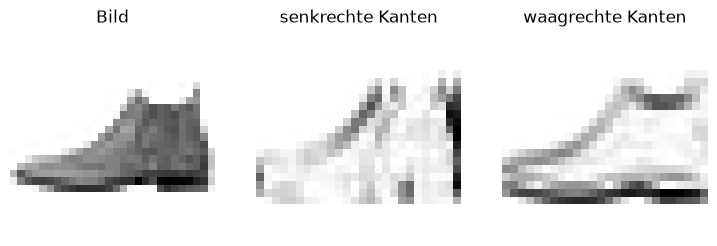

In [5]:
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    train_set = torchvision.datasets.FashionMNIST('data', train=True, download=True, transform=transforms.ToTensor())
    test_set = torchvision.datasets.FashionMNIST('data', train=False, download=True, transform=transforms.ToTensor())
klassen = ['T-Shirt', 'Hose', 'Pullover', 'Kleid', 'Mantel', 'Sandale', 'Hemd', 'Sneaker', 'Tasche', 'Stiefel']

stiefel = test_set[0][0][0]
senkrecht = F.conv2d(stiefel.reshape(1, 1, 28, 28), filter.reshape(1, 1, 3, 3))[0, 0]
waagrecht = F.conv2d(stiefel.reshape(1, 1, 28, 28), filter.T.reshape(1, 1, 3, 3))[0, 0]

plt.figure(figsize=(9, 3))
for i, (b, titel) in enumerate([(stiefel, 'Bild'), (senkrecht.abs(), 'senkrechte Kanten'),
                                (waagrecht.abs(), 'waagrechte Kanten')]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(b, cmap='gray_r')
    plt.title(titel)
    plt.axis('off')
plt.show()

Die Feature Maps zeigen, wo im Bild senkrechte und waagrechte Kanten liegen (dunkel = starke Kante). In einem CNN legt
man die Filterwerte nicht von Hand fest: Sie sind **Parameter**, die das Netz lernt. Frühe Schichten lernen dabei
meist einfache Merkmale wie Kanten, spätere Schichten setzen daraus kompliziertere Formen zusammen.

### Padding und Stride

Ohne weitere Maßnahmen wird das Bild durch die Faltung kleiner: Ein $n \times n$-Bild mit einem $f \times f$-Filter
ergibt ein $(n - f + 1) \times (n - f + 1)$-Bild. Außerdem gehen die Randpixel seltener in das Ergebnis ein.

Beim **Padding** legt man einen Rand aus Nullen um das Bild. Mit Padding $p = 1$ und einem $3 \times 3$-Filter bleibt
die Größe gleich. Beim **Stride** (Schrittweite) rückt der Filter um $s$ Pixel statt um eins weiter. Allgemein gilt
für die Größe des Ergebnisses:

$$\frac{n + 2p - f}{s} + 1 \quad \text{(abgerundet)}$$

In [6]:
print(F.conv2d(bild.reshape(1, 1, 4, 4), filter.reshape(1, 1, 3, 3), padding=1))

b5 = torch.arange(25.0).reshape(1, 1, 5, 5)
print(F.conv2d(b5, filter.reshape(1, 1, 3, 3), stride=2).shape)
print(F.conv2d(torch.zeros(1, 1, 28, 28), torch.zeros(1, 1, 5, 5), padding=2).shape)

tensor([[[[ -5.,  -5.,  -6.,   9.],
          [-12.,  -5.,  -4.,  11.],
          [-13., -10.,  -2.,  13.],
          [ -8.,  -3.,   2.,   5.]]]])
torch.Size([1, 1, 2, 2])
torch.Size([1, 1, 28, 28])


Mit Padding 1 bleibt das $4 \times 4$-Bild $4 \times 4$. Ein $5 \times 5$-Bild mit Stride 2 ergibt
$\frac{5 + 0 - 3}{2} + 1 = 2$, also $2 \times 2$. Ein $28 \times 28$-Bild mit einem $5 \times 5$-Filter und Padding 2
bleibt $28 \times 28$.

### Mehrere Kanäle und mehrere Filter

Ein Farbbild hat drei Kanäle (rot, grün, blau). Ein Filter hat dann ebenfalls drei Kanäle, er ist ein kleiner Quader
mit z.B. $3 \times 3 \times 3$ Zahlen. An jeder Stelle werden alle 27 Produkte zu **einer** Zahl addiert. Ein Filter
erzeugt also immer genau eine Feature Map, egal wie viele Kanäle der Input hat.

Um mehrere Merkmale gleichzeitig zu erkennen, benutzt man mehrere Filter. Jeder erzeugt eine Feature Map, sie werden
als Kanäle hintereinander gestapelt. Zu jedem Filter gehört noch ein Bias. Eine Schicht `nn.Conv2d(3, 10, 3)` hat
3 Input-Kanäle, 10 Filter der Größe $3 \times 3$ und damit $10 \cdot (3 \cdot 3 \cdot 3 + 1) = 280$ Parameter.

In [7]:
schicht = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=3)
print(schicht.weight.shape, schicht.bias.shape)
print(sum(p.numel() for p in schicht.parameters()))

farbbilder = torch.randn(8, 3, 32, 32)
print(schicht(farbbilder).shape)
print(schicht(torch.randn(8, 3, 200, 200)).shape)

torch.Size([10, 3, 3, 3]) torch.Size([10])
280
torch.Size([8, 10, 30, 30])
torch.Size([8, 10, 198, 198])


Aus 8 Farbbildern mit $32 \times 32$ Pixeln werden 8 Stapel aus je 10 Feature Maps mit $30 \times 30$ Pixeln. Die Zahl
der Parameter hängt **nicht** von der Bildgröße ab: Dieselben 280 Parameter verarbeiten auch Bilder mit
$200 \times 200$ Pixeln. Das liegt an zwei Eigenschaften:

- **Parameter Sharing:** Derselbe Filter wird an jeder Stelle des Bildes benutzt. Ein Kantendetektor, der links oben
  nützlich ist, ist es auch rechts unten.
- **Lokale Verbindungen:** Jeder Wert einer Feature Map hängt nur von einem kleinen Ausschnitt des Inputs ab.

### Pooling

Neben Faltungsschichten haben CNNs meist **Pooling**-Schichten. Beim **Max-Pooling** mit Größe 2 und Stride 2 wird
das Bild in $2 \times 2$-Blöcke geteilt, von jedem Block bleibt nur das Maximum. Höhe und Breite halbieren sich.

In [8]:
x = torch.tensor([[3., 0., 1., 2.],
                  [1., 2., 8., 9.],
                  [2., 1., 2., 4.],
                  [0., 1., 3., 1.]])
print(F.max_pool2d(x.reshape(1, 1, 4, 4), kernel_size=2, stride=2))

tensor([[[[3., 9.],
          [2., 4.]]]])


Wenn ein großer Wert bedeutet, dass ein Merkmal gefunden wurde, sorgt Max-Pooling dafür, dass dieser Fund erhalten
bleibt, auch wenn das Merkmal ein, zwei Pixel verschoben ist. Pooling hat keine Parameter.

### Ein CNN für Fashion-MNIST

Typisch ist: erst einige Faltungsschichten (mit ReLU und Pooling), dann eine oder mehrere vollständig verbundene
Schichten. Mit der Tiefe werden die Bilder kleiner, die Zahl der Kanäle steigt.

In [9]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=5, padding=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=5, padding=2)
        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, t):
        t = F.max_pool2d(torch.relu(self.conv1(t)), 2)
        t = F.max_pool2d(torch.relu(self.conv2(t)), 2)
        t = t.reshape(-1, 32 * 7 * 7)
        return self.fc(t)

netz = CNN()
for name, p in netz.named_parameters():
    print(name, p.shape, p.numel())
print('Parameter insgesamt:', sum(p.numel() for p in netz.parameters()))

conv1.weight torch.Size([16, 1, 5, 5]) 400
conv1.bias torch.Size([16]) 16
conv2.weight torch.Size([32, 16, 5, 5]) 12800
conv2.bias torch.Size([32]) 32
fc.weight torch.Size([10, 1568]) 15680
fc.bias torch.Size([10]) 10
Parameter insgesamt: 28938


Der Weg eines Batches von 100 Bildern durch das Netz:

In [10]:
t = torch.zeros(100, 1, 28, 28)
print('Input        ', t.shape)
t = torch.relu(netz.conv1(t))
print('conv1        ', t.shape)
t = F.max_pool2d(t, 2)
print('pool         ', t.shape)
t = torch.relu(netz.conv2(t))
print('conv2        ', t.shape)
t = F.max_pool2d(t, 2)
print('pool         ', t.shape)
t = t.reshape(-1, 32 * 7 * 7)
print('reshape      ', t.shape)
print('fc           ', netz.fc(t).shape)

Input         torch.Size([100, 1, 28, 28])
conv1         torch.Size([100, 16, 28, 28])
pool          torch.Size([100, 16, 14, 14])
conv2         torch.Size([100, 32, 14, 14])
pool          torch.Size([100, 32, 7, 7])
reshape       torch.Size([100, 1568])
fc            torch.Size([100, 10])


Die erste Faltungsschicht macht aus einem Kanal 16, Pooling halbiert auf $14 \times 14$. Die zweite macht 32 Kanäle,
Pooling halbiert auf $7 \times 7$. Diese $32 \cdot 7 \cdot 7 = 1568$ Zahlen gehen in die letzte Schicht. Das ganze Netz
hat nur 28938 Parameter, weniger als ein Drittel des Netzes aus dem letzten Notebook (102070).

Training wie dort, mit Adam:

In [11]:
def trainiere(netz, loader, optimizer):
    netz.train()
    for bilder, labels in loader:
        bilder, labels = bilder.to(device), labels.to(device)
        loss = F.cross_entropy(netz(bilder), labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

def genauigkeit(netz, loader):
    netz.eval()
    richtig = 0
    with torch.no_grad():
        for bilder, labels in loader:
            bilder, labels = bilder.to(device), labels.to(device)
            richtig += (netz(bilder).argmax(dim=1) == labels).sum().item()
    return richtig / len(loader.dataset)

torch.manual_seed(0)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=100, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1000)
netz = CNN().to(device)
optimizer = torch.optim.Adam(netz.parameters(), lr=0.001)

for epoche in range(3):
    start = time.time()
    trainiere(netz, train_loader, optimizer)
    print(f'Epoche {epoche + 1}: Test {genauigkeit(netz, test_loader):.4f}  ({time.time() - start:.0f} s)')

Epoche 1: Test 0.8512  (22 s)


Epoche 2: Test 0.8759  (22 s)


Epoche 3: Test 0.8882  (22 s)


Nach drei Epochen erkennt das CNN fast 89 Prozent der Testbilder. Das Netz aus dem letzten Notebook kam mit gut
dreimal so vielen Parametern auf etwa 86 Prozent.

#### Was das CNN gelernt hat

Die 16 Filter der ersten Schicht sind jetzt gelernte $5 \times 5$-Bilder:

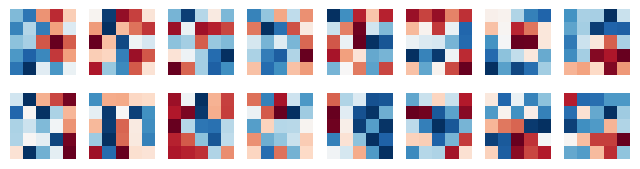

In [12]:
filter1 = netz.conv1.weight.detach().cpu()
plt.figure(figsize=(8, 2))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(filter1[i, 0], cmap='RdBu')
    plt.axis('off')
plt.show()

Rot sind positive, blau negative Werte. Saubere Kantenfilter wie unser Beispiel von Hand sieht man nach drei Epochen
nicht, aber viele Filter haben positive und negative Bereiche nebeneinander. Deutlicher wird es, wenn man sich
ansieht, was die Filter aus dem Stiefel machen, also die Feature Maps der ersten Schicht:

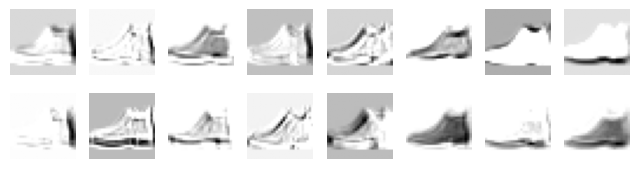

In [13]:
with torch.no_grad():
    maps = torch.relu(netz.conv1(test_set[0][0].reshape(1, 1, 28, 28).to(device)))[0].cpu()
plt.figure(figsize=(8, 2))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(maps[i], cmap='gray_r')
    plt.axis('off')
plt.show()

Manche Feature Maps heben die Umrisse des Stiefels hervor, andere seine Fläche oder den Hintergrund. Die zweite
Faltungsschicht setzt aus diesen 16 Karten wieder neue Merkmale zusammen.

### Berühmte Architekturen

- **LeNet-5** (Yann LeCun, 1998) erkannte handgeschriebene Ziffern, z.B. auf Schecks. Es hatte etwa 60000 Parameter
  und schon den typischen Aufbau: Faltung und Pooling, dann vollständig verbundene Schichten.
- **AlexNet** (Alex Krizhevsky, Ilya Sutskever, Geoffrey Hinton, 2012) gewann den Wettbewerb ImageNet mit großem
  Abstand: 1,2 Millionen Fotos in 1000 Klassen. Es hatte etwa 60 Millionen Parameter, benutzte ReLU und wurde auf
  Grafikkarten trainiert. Danach setzten sich neuronale Netze in der Bilderkennung durch.
- **VGG-16** (2014) hat 16 Schichten mit sehr regelmäßigem Aufbau (nur $3 \times 3$-Filter) und etwa 138 Millionen
  Parameter.
- **ResNet** (2015): Sehr tiefe Netze lassen sich schlecht trainieren, die Ableitungen verschwinden auf dem Weg zurück
  (siehe Backpropagation). ResNet führt **Skip Connections** ein: Der Input einer Schicht wird zu ihrem Output addiert,
  $a = f(x) + x$. Auf diesem Umweg kommt das Fehlersignal ungeschwächt zurück. So wurden Netze mit über 100 Schichten
  möglich.

Seit etwa 2020 werden für Bilder auch **Vision Transformer** benutzt, die mit dem Attention-Mechanismus der
Sprachmodelle arbeiten (siehe Sprachmodelle).

### Transfer Learning

Ein großes Netz wie ResNet zu trainieren braucht Millionen Bilder und viel Rechenzeit. Man kann aber ein bereits
trainiertes Netz benutzen. PyTorch bietet ResNet18, trainiert auf ImageNet. Die Gewichte (etwa 45 MB) werden beim
ersten Aufruf heruntergeladen.

In [14]:
gewichte = torchvision.models.ResNet18_Weights.DEFAULT
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    resnet = torchvision.models.resnet18(weights=gewichte)
resnet = resnet.to(device).eval()
kategorien = gewichte.meta['categories']
print('Parameter:', sum(p.numel() for p in resnet.parameters()))
print(len(kategorien), kategorien[:5])

Parameter: 11689512
1000 ['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead']


ResNet18 erwartet Farbbilder mit $224 \times 224$ Pixeln, deren Farbwerte wie bei ImageNet normiert sind. Die
Fashion-Bilder vergrößern wir deshalb und kopieren den Graukanal in alle drei Farbkanäle. Was sagt ResNet18 zu
einigen Testbildern, ohne dass es Fashion-MNIST je gesehen hat?

In [15]:
normieren = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

def vorbereiten(bilder, groesse):
    bilder = F.interpolate(bilder, size=groesse, mode='bilinear')
    return normieren(bilder.repeat(1, 3, 1, 1))

bilder = torch.stack([test_set[i][0] for i in range(8)])
with torch.no_grad():
    vorhersage = resnet(vorbereiten(bilder, 224).to(device)).argmax(dim=1).cpu()
for i in range(8):
    print(f'{klassen[test_set[i][1]]:10} ResNet18: {kategorien[vorhersage[i]]}')

Stiefel    ResNet18: hatchet
Pullover   ResNet18: oil filter
Hose       ResNet18: can opener
Hose       ResNet18: pedestal
Hemd       ResNet18: knee pad
Hose       ResNet18: pedestal
Mantel     ResNet18: cloak
Hemd       ResNet18: cocktail shaker


ResNet18 kennt die Fashion-Klassen nicht, seine 1000 ImageNet-Klassen sind Tiere, Fahrzeuge, Gegenstände usw. Die
meisten Antworten passen deshalb nicht, nur beim Mantel liegt es mit *cloak* (Umhang) nah dran. Die kleinen
Graustufenbilder sehen auch ganz anders aus als die Fotos, mit denen ResNet18 trainiert wurde. Trotzdem haben die
Schichten vor der letzten gelernt, allgemeine Merkmale von Bildern zu erkennen.

Beim **Transfer Learning** nutzt man genau das: Man behält alle Schichten bis auf die letzte, friert ihre Gewichte
ein und trainiert nur eine neue letzte Schicht für die eigenen Klassen. ResNet18 liefert vor der letzten Schicht 512
Merkmale pro Bild. Wir berechnen sie einmal für 2000 Trainings- und 1000 Testbilder (in $112 \times 112$ Pixeln, das
geht schneller) und trainieren dann nur eine Schicht `nn.Linear(512, 10)`.

In [16]:
resnet.fc = nn.Identity()

def merkmale(datensatz, anzahl):
    loader = torch.utils.data.DataLoader(torch.utils.data.Subset(datensatz, range(anzahl)), batch_size=100)
    alle, labels = [], []
    with torch.no_grad():
        for bilder, l in loader:
            alle.append(resnet(vorbereiten(bilder, 112).to(device)).cpu())
            labels.append(l)
    return torch.cat(alle), torch.cat(labels)

start = time.time()
X_train, y_train = merkmale(train_set, 2000)
X_test, y_test = merkmale(test_set, 1000)
print(X_train.shape, f'({time.time() - start:.0f} s)')

torch.manual_seed(0)
kopf = nn.Linear(512, 10)
optimizer = torch.optim.Adam(kopf.parameters(), lr=0.001)
for schritt in range(100):
    loss = F.cross_entropy(kopf(X_train), y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
with torch.no_grad():
    print('Transfer Learning, Test:', (kopf(X_test).argmax(dim=1) == y_test).float().mean().item())

torch.Size([2000, 512]) (19 s)


Transfer Learning, Test: 0.8489999771118164


Zum Vergleich trainieren wir unser CNN von Grund auf mit denselben 2000 Bildern:

In [17]:
torch.manual_seed(0)
klein_loader = torch.utils.data.DataLoader(torch.utils.data.Subset(train_set, range(2000)), batch_size=100, shuffle=True)
test1000 = torch.utils.data.DataLoader(torch.utils.data.Subset(test_set, range(1000)), batch_size=1000)
cnn_klein = CNN().to(device)
optimizer = torch.optim.Adam(cnn_klein.parameters(), lr=0.001)
for epoche in range(20):
    trainiere(cnn_klein, klein_loader, optimizer)
print('CNN von Grund auf, Test:', genauigkeit(cnn_klein, test1000))

CNN von Grund auf, Test: 0.824


Mit nur 2000 Bildern ist Transfer Learning besser als das eigene CNN, obwohl dabei nur die 5130 Parameter der letzten
Schicht gelernt wurden. Das Vorwissen aus Millionen ImageNet-Fotos hilft auch bei Kleidungsstücken. So arbeitet man in
der Praxis oft: Man nimmt ein vortrainiertes Netz und passt es mit wenigen eigenen Beispielen an.

### Zusammenfassung

- Eine **Faltung** schiebt einen kleinen Filter über das Bild und berechnet an jeder Stelle eine gewichtete Summe. Die
  Filterwerte sind Parameter, die das Netz lernt. Frühe Schichten erkennen z.B. Kanten.
- Die Größe des Ergebnisses ist $\frac{n + 2p - f}{s} + 1$ mit **Padding** $p$ und **Stride** $s$.
- Ein Filter hat so viele Kanäle wie der Input und erzeugt eine Feature Map. Mehrere Filter ergeben mehrere Kanäle.
  Eine Faltungsschicht hat (Filtergröße mal Input-Kanäle plus 1) mal Anzahl der Filter Parameter, unabhängig von der
  Bildgröße.
- **Max-Pooling** verkleinert das Bild und behält die größten Werte.
- Ein kleines CNN erkennt Fashion-MNIST besser als ein vollständig verbundenes Netz mit dreimal so vielen Parametern.
- **Transfer Learning** benutzt ein vortrainiertes Netz und lernt nur die letzte Schicht neu.

Im nächsten Notebook geht es um **Sprachmodelle**.